# Redis & Key-Value Stores

**Redis** is an in-memory **key-value store**: you store a value under a key and read it back in well under a millisecond. Redis also offers data structures (lists, sets, sorted sets, hashes, streams) and automatic expiry. It is the standard tool for caches, counters, rate limiters, queues and leaderboards.

**After this lesson you can:**

1. Use strings, hashes, lists, sets and sorted sets.
2. Set expiry times (TTL) and build a cache in front of PostgreSQL.
3. Implement a rate limiter and a leaderboard.
4. Measure the latency gain of a cache.

The lesson uses real Redis and PostgreSQL servers (Docker, profile `db`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

import json
import time

import redis

datasets.ensure_service("db", "redis")
r = redis.Redis(host="localhost", port=6379, decode_responses=True)
r.flushdb()
print("Redis", r.info()["redis_version"], "| PING ->", r.ping())

Redis 7.4.12 | PING -> True


## 1. Data Structures

| Type | Commands | Use |
| :--- | :--- | :--- |
| string | `SET`, `GET`, `INCR`, `EXPIRE` | cache entries, counters, flags |
| hash | `HSET`, `HGETALL` | small objects (a user profile) |
| list | `LPUSH`, `RPOP`, `LRANGE` | queues, recent items |
| set | `SADD`, `SISMEMBER`, `SINTER` | unique members, tags |
| sorted set | `ZADD`, `ZINCRBY`, `ZREVRANGE` | leaderboards, rankings, time indexes |

In [2]:
r.set("greeting", "merhaba")
r.incr("page:views"); r.incr("page:views"); r.incrby("page:views", 10)
r.hset("user:42", mapping={"name": "Ayse", "plan": "pro", "country": "TR"})
r.lpush("recent:searches", "jazz", "metal", "bossa nova")
r.sadd("tags:track:1", "rock", "classic", "70s")
print("string :", r.get("greeting"))
print("counter:", r.get("page:views"))
print("hash   :", r.hgetall("user:42"))
print("list   :", r.lrange("recent:searches", 0, -1))
print("set    :", sorted(r.smembers("tags:track:1")), "| is 'rock' a tag?", r.sismember("tags:track:1", "rock"))

string : merhaba
counter: 12
hash   : {'name': 'Ayse', 'plan': 'pro', 'country': 'TR'}
list   : ['bossa nova', 'metal', 'jazz']
set    : ['70s', 'classic', 'rock'] | is 'rock' a tag? 1


## 2. Expiry (TTL)

`SET key value EX seconds` stores a value that Redis deletes automatically after the given time. `TTL key` shows the remaining seconds. Expiry keeps a cache fresh and bounds its memory use.

In [3]:
r.set("session:abc", "user:42", ex=2)
print("TTL now:", r.ttl("session:abc"), "s | value:", r.get("session:abc"))
time.sleep(2.2)
print("after 2.2 s -> value:", r.get("session:abc"))

TTL now: 2 s | value: user:42


after 2.2 s -> value: None


## 3. Cache-Aside in Front of PostgreSQL

The **cache-aside** pattern:

1. Look for the result in Redis.
2. On a **hit**, return it.
3. On a **miss**, run the database query, store the result in Redis with a TTL, and return it.

The cached query computes the sales report of one artist from Chinook (several joins).

In [4]:
REPORT_SQL = """
SELECT ar.name AS artist, count(*) AS lines_sold, sum(il.unit_price * il.quantity) AS revenue
FROM invoice_line il JOIN track t ON t.track_id = il.track_id
JOIN album al ON al.album_id = t.album_id JOIN artist ar ON ar.artist_id = al.artist_id
WHERE ar.artist_id = :artist_id
GROUP BY ar.name
"""

def artist_report(artist_id: int, ttl: int = 60) -> dict:
    key = f"report:artist:{artist_id}"
    cached = r.get(key)
    if cached is not None:
        return json.loads(cached)
    row = q(REPORT_SQL, artist_id=artist_id).to_dict("records")[0]
    row = {k: (float(v) if k == "revenue" else v) for k, v in row.items()}
    r.set(key, json.dumps(row), ex=ttl)
    return row

artist_ids = q("SELECT DISTINCT al.artist_id FROM album al JOIN track t USING (album_id) JOIN invoice_line USING (track_id)")["artist_id"].tolist()[:30]
r.delete(*[f"report:artist:{a}" for a in artist_ids])
miss_ms, hit_ms = [], []
for a in artist_ids:
    t = time.perf_counter(); artist_report(a); miss_ms.append((time.perf_counter() - t) * 1000)
for a in artist_ids:
    t = time.perf_counter(); artist_report(a); hit_ms.append((time.perf_counter() - t) * 1000)
print(artist_report(artist_ids[0]))
print(f"median latency: miss (PostgreSQL) {sorted(miss_ms)[15]:.2f} ms | hit (Redis) {sorted(hit_ms)[15]:.3f} ms")

{'artist': 'Passengers', 'lines_sold': 9, 'revenue': 8.91}
median latency: miss (PostgreSQL) 5.39 ms | hit (Redis) 0.222 ms


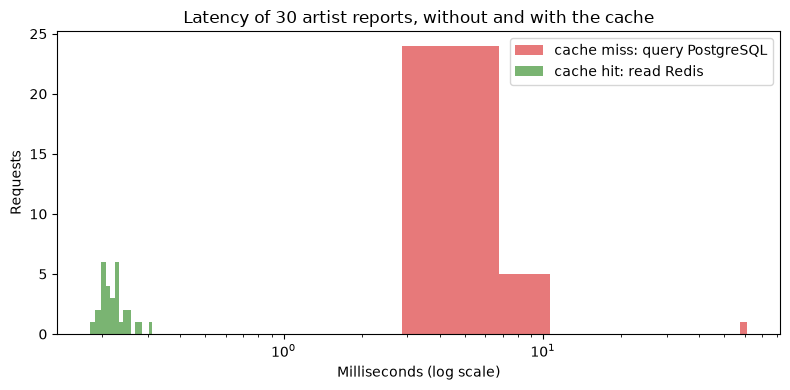

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(miss_ms, bins=15, alpha=0.8, color="#E15759", label="cache miss: query PostgreSQL")
ax.hist(hit_ms, bins=15, alpha=0.8, color="#59A14F", label="cache hit: read Redis")
ax.set(xscale="log", title="Latency of 30 artist reports, without and with the cache", xlabel="Milliseconds (log scale)",
       ylabel="Requests")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Rate Limiting

A **rate limiter** allows each client at most *N* requests per time window. The simplest version is a **fixed window counter**: `INCR` a key that contains the current window, and set an expiry on the first increment. Redis executes `INCR` atomically, so the counter is correct with many concurrent servers.

33 requests in 3 s, 16 allowed, 17 rejected (limit 5 per second)


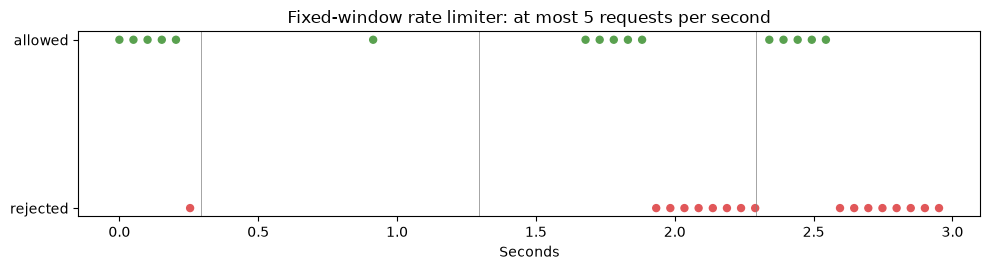

In [6]:
def allow(client: str, limit: int = 5, window_s: int = 1) -> bool:
    key = f"rate:{client}:{int(time.time() // window_s)}"
    with r.pipeline() as p:
        p.incr(key)
        p.expire(key, window_s * 2)
        count, _ = p.execute()
    return count <= limit

decisions = []
start = time.time()
while time.time() - start < 3:
    decisions.append((time.time() - start, allow("api-key-123")))
    time.sleep(0.05)
allowed = sum(ok for _, ok in decisions)
print(f"{len(decisions)} requests in 3 s, {allowed} allowed, {len(decisions) - allowed} rejected (limit 5 per second)")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.scatter([t for t, ok in decisions], [1 if ok else 0 for _, ok in decisions],
           c=["#59A14F" if ok else "#E15759" for _, ok in decisions], s=25)
ax.set_yticks([0, 1], ["rejected", "allowed"])
for s in range(1, 4):
    ax.axvline(s - (start % 1), color="grey", lw=0.5)
ax.set(title="Fixed-window rate limiter: at most 5 requests per second", xlabel="Seconds")
plt.tight_layout()
plt.show()

## 5. A Leaderboard with a Sorted Set

A **sorted set** keeps members ordered by a score. `ZINCRBY` updates a score in $O(\log n)$; `ZREVRANGE` returns the top members. The cell builds a "most purchased tracks" leaderboard from the Chinook invoice lines.

In [7]:
sales = q("SELECT t.name AS track, il.quantity FROM invoice_line il JOIN track t ON t.track_id = il.track_id")
with r.pipeline() as p:
    for row in sales.itertuples(index=False):
        p.zincrby("leaderboard:tracks", row.quantity, row.track)
    p.execute()
print("tracks on the leaderboard:", r.zcard("leaderboard:tracks"))
top = r.zrevrange("leaderboard:tracks", 0, 4, withscores=True)
pd.DataFrame(top, columns=["track", "units"])

tracks on the leaderboard: 1888


,track,units
0,The Trooper,5.0
1,Untitled,4.0
2,The Number Of The Beast,4.0
3,Sure Know Something,4.0
4,Hallowed Be Thy Name,4.0


*Insight: Put Redis in front of slow or expensive work (database queries, API calls, LLM responses) with a TTL that matches how fresh the data must be. Remember that a cache can serve stale data, and that Redis keeps data in memory: treat it as a fast copy, not as the only copy of important data.*

## Real-World Use Case or Analogy

Redis is like the **counter of a busy café**: the most popular cakes sit on the counter (the cache) so the waiter does not walk to the kitchen (the database) for every order. A label on each plate says when to throw it away (the TTL). The ticket roll at the entrance (the rate limiter) makes sure the kitchen is not overwhelmed.

Web applications cache sessions and pages in Redis, APIs use it for rate limiting, games use sorted sets for leaderboards, and LLM applications use it for **semantic caching** of answers (M30).